<a href="https://colab.research.google.com/github/SmdIoufy/Gestion-Tontine/blob/master/P_DNN_BankingT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP de Deep Learning : prédiction de souscription bancaire

## 1. Objectif

L'objectif de ce TP est de construire un réseau de neurones artificiels (DNN) capable de prédire si un client souscrira ou non à un dépôt bancaire à terme.

## 2. Jeu de données

Nous utiliserons le fichier `banking_dataset.csv`, qui contient des informations sur des clients et des campagnes de marketing bancaire.

## 3. Méthode de travail

1. Importer les bibliothèques.
2. Charger et explorer les données.
3. Préparer les variables pour le modèle.
4. Construire le réseau de neurones.
5. Compiler et entraîner le modèle.
6. Évaluer les performances.
7. Tester des prédictions.
8. Étudier le déploiement avec Gradio.

In [4]:

# 1. Manipulation et exploration des données
import pandas as pd
import numpy as np

# 2. Préparation des données
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 3. Construction du réseau de neurones
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 4. Évaluation du modèle
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 5. Affichage des graphiques
import matplotlib.pyplot as plt
import seaborn as sns

# Vérification de l'environnement
print("Version de NumPy :", np.__version__)
print("Version de TensorFlow :", tf.__version__)


Version de NumPy : 2.1.3
Version de TensorFlow : 2.21.0


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
df = pd.read_csv("banking_dataset.csv")

In [ ]:
display(df.head())

In [7]:

# Afficher le nombre de lignes et de colonnes
print("Dimensions du dataset :", df.shape)

# Afficher les informations sur les colonnes
df.info()


Dimensions du dataset : (41188, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          41188 non-null  int64 
 1   job          41188 non-null  object
 2   marital      41188 non-null  object
 3   education    41188 non-null  object
 4   default      41188 non-null  object
 5   housing      41188 non-null  object
 6   loan         41188 non-null  object
 7   contact      41188 non-null  object
 8   month        41188 non-null  object
 9   day_of_week  41188 non-null  object
 10  duration     41188 non-null  int64 
 11  campaign     41188 non-null  int64 
 12  pdays        41188 non-null  int64 
 13  previous     41188 non-null  int64 
 14  poutcome     41188 non-null  object
 15  y            41188 non-null  object
dtypes: int64(5), object(11)
memory usage: 5.0+ MB


In [8]:

# Compter les valeurs manquantes dans chaque colonne
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())

# Compter le nombre de lignes dupliquées
print("\nNombre de lignes dupliquées :", df.duplicated().sum())


Valeurs manquantes par colonne :
age            0
job            0
marital        0
education      0
default        0
housing        0
loan           0
contact        0
month          0
day_of_week    0
duration       0
campaign       0
pdays          0
previous       0
poutcome       0
y              0
dtype: int64

Nombre de lignes dupliquées : 13


In [9]:

# Compter les clients dans chaque classe
print("Répartition de la variable cible :")
print(df["y"].value_counts())

# Calculer les proportions en pourcentage
print("\nRépartition en pourcentage :")
print((df["y"].value_counts(normalize=True) * 100).round(2))


Répartition de la variable cible :
y
no     36548
yes     4640
Name: count, dtype: int64

Répartition en pourcentage :
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


In [10]:

# Résumé statistique des variables numériques
display(df.describe())

# Nombre de catégories différentes par colonne
print("Nombre de valeurs distinctes par colonne :")
print(df.nunique())


,age,duration,campaign,pdays,previous
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963
std,10.42125,259.279249,2.770014,186.910907,0.494901
min,17.00000,0.000000,1.000000,0.000000,0.000000
25%,32.00000,102.000000,1.000000,999.000000,0.000000
50%,38.00000,180.000000,2.000000,999.000000,0.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000
max,98.00000,4918.000000,56.000000,999.000000,7.000000


Nombre de valeurs distinctes par colonne :
age              78
job              12
marital           4
education         8
default           3
housing           3
loan              3
contact           2
month            10
day_of_week       5
duration       1544
campaign         42
pdays            27
previous          8
poutcome          3
y                 2
dtype: int64


In [11]:

# Rechercher les catégories "unknown" dans les colonnes textuelles
for col in df.select_dtypes(include="object").columns:
    nb_unknown = (df[col] == "unknown").sum()
    if nb_unknown > 0:
        print(f"{col} : {nb_unknown} valeurs unknown")


job : 330 valeurs unknown
marital : 80 valeurs unknown
education : 1731 valeurs unknown
default : 8597 valeurs unknown
housing : 990 valeurs unknown
loan : 990 valeurs unknown


In [12]:

# Séparer les variables explicatives et la variable cible
X = df.drop(columns=["y", "duration"])
y = df["y"]

# Afficher les dimensions obtenues
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

# Afficher les premières lignes de X
display(X.head())

# Afficher les premières valeurs de y
display(y.head())


Dimensions de X : (41188, 14)
Dimensions de y : (41188,)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,1,999,0,nonexistent
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,1,999,0,nonexistent
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,3,6,2,success
3,39,services,married,high.school,no,no,no,cellular,apr,fri,2,999,0,nonexistent
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,1,3,1,success


,y
0,no
1,no
2,yes
3,no
4,yes


In [13]:

# Identifier les colonnes numériques
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Identifier les colonnes catégorielles
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

# Afficher les colonnes détectées
print("Variables numériques :", numeric_features)
print("\nNombre de variables numériques :", len(numeric_features))

print("\nVariables catégorielles :", categorical_features)
print("\nNombre de variables catégorielles :", len(categorical_features))


Variables numériques : ['age', 'campaign', 'pdays', 'previous']

Nombre de variables numériques : 4

Variables catégorielles : ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Nombre de variables catégorielles : 10


In [14]:

# Préparation des variables numériques
numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Préparation des variables catégorielles
categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Appliquer chaque préparation aux colonnes appropriées
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Les transformateurs sont configurés.")


Les transformateurs sont configurés.


In [15]:

# Séparer les données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Vérifier les dimensions
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)


X_train : (32950, 14)
X_test  : (8238, 14)
y_train : (32950,)
y_test  : (8238,)


In [16]:
# Apprendre les transformations à partir des données d'entraînement
# puis transformer X_train
X_train_processed = preprocessor.fit_transform(X_train)

# Appliquer les mêmes transformations aux données de test
X_test_processed = preprocessor.transform(X_test)

# Vérifier les dimensions obtenues
print("Dimensions de X_train_processed :", X_train_processed.shape)
print("Dimensions de X_test_processed  :", X_test_processed.shape)

Dimensions de X_train_processed : (32950, 57)
Dimensions de X_test_processed  : (8238, 57)


In [17]:
# Transformer la variable cible en valeurs numériques
y_train_processed = y_train.map({"no": 0, "yes": 1})
y_test_processed = y_test.map({"no": 0, "yes": 1})

# Vérifier les premières valeurs
print("Premières valeurs de y_train_processed :")
print(y_train_processed.head())

# Vérifier qu'aucune valeur n'a été oubliée
print("\nValeurs présentes dans y_train_processed :")
print(y_train_processed.unique())

Premières valeurs de y_train_processed :
27549    0
27965    0
36497    1
315      0
38191    0
Name: y, dtype: int64

Valeurs présentes dans y_train_processed :
[0 1]


In [18]:
# Vérifier les dimensions des données préparées
print("X_train_processed :", X_train_processed.shape)
print("X_test_processed  :", X_test_processed.shape)

print("y_train_processed :", y_train_processed.shape)
print("y_test_processed  :", y_test_processed.shape)

# Vérifier les valeurs manquantes
print("\nValeurs manquantes dans X_train :",
      np.isnan(X_train_processed).sum())

print("Valeurs manquantes dans X_test :",
      np.isnan(X_test_processed).sum())

print("Valeurs manquantes dans y_train :",
      y_train_processed.isna().sum())

print("Valeurs manquantes dans y_test :",
      y_test_processed.isna().sum())

X_train_processed : (32950, 57)
X_test_processed  : (8238, 57)
y_train_processed : (32950,)
y_test_processed  : (8238,)


TypeError: ufunc 'isnan' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

In [19]:
print("Type de X_train_processed :",
      type(X_train_processed))

print("Type de données internes :",
      X_train_processed.dtype)

print("Type de X_test_processed :",
      type(X_test_processed))

print("Type de données internes du test :",
      X_test_processed.dtype)

Type de X_train_processed : <class 'scipy.sparse._csr.csr_matrix'>
Type de données internes : float64
Type de X_test_processed : <class 'scipy.sparse._csr.csr_matrix'>
Type de données internes du test : float64


In [20]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=0
)

print("Préprocesseur configuré pour produire un tableau dense.")

Préprocesseur configuré pour produire un tableau dense.


In [21]:
# Transformer les données d'entraînement
X_train_processed = preprocessor.fit_transform(X_train)

# Appliquer les mêmes transformations aux données de test
X_test_processed = preprocessor.transform(X_test)

# Vérifier les types et les dimensions
print("Type de X_train_processed :", type(X_train_processed))
print("Type de X_test_processed  :", type(X_test_processed))

print("\nDimensions de X_train_processed :", X_train_processed.shape)
print("Dimensions de X_test_processed  :", X_test_processed.shape)

Type de X_train_processed : <class 'numpy.ndarray'>
Type de X_test_processed  : <class 'numpy.ndarray'>

Dimensions de X_train_processed : (32950, 57)
Dimensions de X_test_processed  : (8238, 57)


In [22]:
# Vérifier les valeurs manquantes dans les variables explicatives
print("Valeurs manquantes dans X_train :",
      np.isnan(X_train_processed).sum())

print("Valeurs manquantes dans X_test :",
      np.isnan(X_test_processed).sum())

# Vérifier les valeurs manquantes dans la cible
print("Valeurs manquantes dans y_train :",
      y_train_processed.isna().sum())

print("Valeurs manquantes dans y_test :",
      y_test_processed.isna().sum())

Valeurs manquantes dans X_train : 0
Valeurs manquantes dans X_test : 0
Valeurs manquantes dans y_train : 0
Valeurs manquantes dans y_test : 0


In [23]:

# Vérifier les dimensions des données prétraitées
print("Dimensions de X_train :", X_train_processed.shape)
print("Dimensions de X_test :", X_test_processed.shape)

# Vérifier les dimensions des cibles
print("Dimensions de y_train :", y_train_processed.shape)
print("Dimensions de y_test :", y_test_processed.shape)

# Vérifier les types des données
print("Type de X_train :", X_train_processed.dtype)
print("Type de y_train :", y_train_processed.dtype)

# Vérifier les classes de la cible
print("Classes de y_train :", np.unique(y_train_processed))
print("Répartition des classes :")
print(y_train_processed.value_counts())


Dimensions de X_train : (32950, 57)
Dimensions de X_test : (8238, 57)
Dimensions de y_train : (32950,)
Dimensions de y_test : (8238,)
Type de X_train : float64
Type de y_train : int64
Classes de y_train : [0 1]
Répartition des classes :
y
0    29238
1     3712
Name: count, dtype: int64


In [24]:

# Vérifier les dimensions des données prétraitées
print("Dimensions de X_train :", X_train_processed.shape)
print("Dimensions de X_test :", X_test_processed.shape)

# Vérifier les dimensions des cibles
print("Dimensions de y_train :", y_train_processed.shape)
print("Dimensions de y_test :", y_test_processed.shape)

# Vérifier les types des données
print("Type de X_train :", X_train_processed.dtype)
print("Type de y_train :", y_train_processed.dtype)

# Vérifier les classes de la cible
print("Classes de y_train :", np.unique(y_train_processed))
print("Répartition des classes :")
print(y_train_processed.value_counts())


Dimensions de X_train : (32950, 57)
Dimensions de X_test : (8238, 57)
Dimensions de y_train : (32950,)
Dimensions de y_test : (8238,)
Type de X_train : float64
Type de y_train : int64
Classes de y_train : [0 1]
Répartition des classes :
y
0    29238
1     3712
Name: count, dtype: int64


In [25]:

from tensorflow.keras import Sequential

# Initialiser un réseau de neurones séquentiel
model = Sequential()

# Afficher le modèle
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [28]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense

# Initialiser le modèle et déclarer les 57 variables d'entrée
model = Sequential([
    Input(shape=(57,)),

    # Première couche cachée : 32 neurones
    Dense(32, activation="relu")
])

# Ajouter la couche de sortie
model.add(Dense(1, activation="sigmoid"))

# Afficher le résumé du modèle
model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32)             │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,889 (7.38 KB)

 Trainable params: 1,889 (7.38 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [30]:
history = model.fit(
    X_train_processed,
    y_train_processed,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.8915 - loss: 0.3136 - val_accuracy: 0.8936 - val_loss: 0.3059
Epoch 2/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8993 - loss: 0.2884 - val_accuracy: 0.8894 - val_loss: 0.3053
Epoch 3/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8988 - loss: 0.2859 - val_accuracy: 0.8930 - val_loss: 0.3040
Epoch 4/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9002 - loss: 0.2843 - val_accuracy: 0.8921 - val_loss: 0.3031
Epoch 5/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9010 - loss: 0.2828 - val_accuracy: 0.8936 - val_loss: 0.3027
Epoch 6/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9006 - loss: 0.2817 - val_accuracy: 0.8927 - val_loss: 0.3025
Epoch 7/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9011 - loss: 0.2800 - val_accuracy: 0.8941 - val_loss: 0.3036
Epoch 8/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9011 - loss: 0.2786 - val_accuracy: 0.

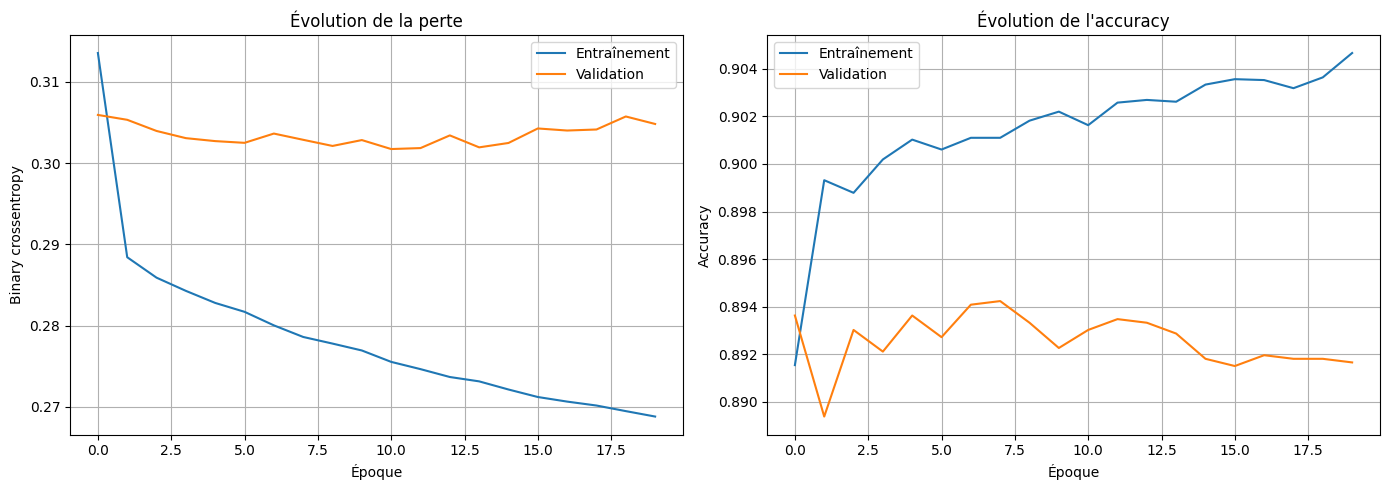

In [31]:
# Créer deux graphiques côte à côte
plt.figure(figsize=(14, 5))

# Graphique 1 : évolution de la perte
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Entraînement")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Évolution de la perte")
plt.xlabel("Époque")
plt.ylabel("Binary crossentropy")
plt.legend()
plt.grid(True)

# Graphique 2 : évolution de l'accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Entraînement")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Évolution de l'accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [32]:
# 1. Prédire les probabilités de souscription
y_proba = model.predict(X_test_processed)

# 2. Convertir les probabilités en classes 0 ou 1
y_pred = (y_proba >= 0.5).astype(int).ravel()

# 3. Afficher quelques résultats
print("Premières probabilités prédites :")
print(y_proba[:10].ravel())

print("\nPremières classes prédites :")
print(y_pred[:10])

print("\nPremières vraies classes :")
print(y_test_processed.iloc[:10].to_numpy())

258/258 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Premières probabilités prédites :
[0.14435895 0.06492602 0.1149711  0.0383176  0.05723584 0.12351915
 0.05936403 0.03757043 0.19909282 0.03451307]

Premières classes prédites :
[0 0 0 0 0 0 0 0 0 0]

Premières vraies classes :
[0 0 0 0 0 0 0 0 1 0]


In [33]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Calculer la matrice de confusion
cm = confusion_matrix(y_test_processed, y_pred)

print("Matrice de confusion :")
print(cm)

# Calculer l'accuracy globale
print("\nAccuracy :", accuracy_score(y_test_processed, y_pred))

# Afficher precision, recall et F1-score pour chaque classe
print("\nRapport de classification :")
print(
    classification_report(
        y_test_processed,
        y_pred,
        target_names=["no (0)", "yes (1)"],
        zero_division=0
    )
)

Matrice de confusion :
[[7208  102]
 [ 749  179]]

Accuracy : 0.896698227725176

Rapport de classification :
              precision    recall  f1-score   support

      no (0)       0.91      0.99      0.94      7310
     yes (1)       0.64      0.19      0.30       928

    accuracy                           0.90      8238
   macro avg       0.77      0.59      0.62      8238
weighted avg       0.88      0.90      0.87      8238



In [34]:
from sklearn.metrics import confusion_matrix, classification_report

# Tester un seuil de décision de 0.30
seuil = 0.30

y_pred_30 = (y_proba >= seuil).astype(int).ravel()

print("Matrice de confusion avec le seuil de 0.30 :")
print(confusion_matrix(y_test_processed, y_pred_30))

print("\nRapport de classification :")
print(
    classification_report(
        y_test_processed,
        y_pred_30,
        target_names=["no (0)", "yes (1)"],
        zero_division=0
    )
)

Matrice de confusion avec le seuil de 0.30 :
[[6997  313]
 [ 612  316]]

Rapport de classification :
              precision    recall  f1-score   support

      no (0)       0.92      0.96      0.94      7310
     yes (1)       0.50      0.34      0.41       928

    accuracy                           0.89      8238
   macro avg       0.71      0.65      0.67      8238
weighted avg       0.87      0.89      0.88      8238



In [ ]:
a

In [35]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Identifier les classes présentes dans les données d'entraînement
classes = np.unique(y_train_processed)

# Calculer un poids adapté à chaque classe
poids_classes = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_processed
)

# Associer chaque classe à son poids
class_weight = dict(zip(classes, poids_classes))

print("Poids des classes :", class_weight)

Poids des classes : {np.int64(0): np.float64(0.5634790341336616), np.int64(1): np.float64(4.438308189655173)}


In [36]:
# Réinitialiser les poids du modèle avec une nouvelle initialisation
model = Sequential([
    Input(shape=(57,)),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

# Configurer le modèle
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Réentraîner en accordant plus d'importance à la classe yes
history_weighted = model.fit(
    X_train_processed,
    y_train_processed,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weight,
    verbose=1
)

Epoch 1/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.7338 - loss: 0.5869 - val_accuracy: 0.7959 - val_loss: 0.5446
Epoch 2/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.7877 - loss: 0.5603 - val_accuracy: 0.7968 - val_loss: 0.5386
Epoch 3/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7966 - loss: 0.5538 - val_accuracy: 0.8358 - val_loss: 0.5068
Epoch 4/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8046 - loss: 0.5495 - val_accuracy: 0.8305 - val_loss: 0.5235
Epoch 5/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8101 - loss: 0.5451 - val_accuracy: 0.7146 - val_loss: 0.6197
Epoch 6/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8065 - loss: 0.5421 - val_accuracy: 0.8247 - val_loss: 0.5188
Epoch 7/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8123 - loss: 0.5394 - val_accuracy: 0.7991 - val_loss: 0.5589
Epoch 8/20
824/824 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8111 - loss: 0.5362 - val_accuracy: 0.

In [37]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Prédire les probabilités sur le jeu de test
y_proba_weighted = model.predict(X_test_processed)

# Convertir les probabilités en classes avec le seuil 0.5
y_pred_weighted = (y_proba_weighted >= 0.5).astype(int).ravel()

# Afficher la matrice de confusion
print("Matrice de confusion :")
print(confusion_matrix(y_test_processed, y_pred_weighted))

# Afficher les métriques
print("\nAccuracy :", accuracy_score(y_test_processed, y_pred_weighted))

print("\nRapport de classification :")
print(
    classification_report(
        y_test_processed,
        y_pred_weighted,
        target_names=["no (0)", "yes (1)"],
        zero_division=0
    )
)

258/258 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
Matrice de confusion :
[[5669 1641]
 [ 349  579]]

Accuracy : 0.7584365137169216

Rapport de classification :
              precision    recall  f1-score   support

      no (0)       0.94      0.78      0.85      7310
     yes (1)       0.26      0.62      0.37       928

    accuracy                           0.76      8238
   macro avg       0.60      0.70      0.61      8238
weighted avg       0.87      0.76      0.80      8238



In [38]:
%pip install -q gradio

In [41]:
# Vérifier que le modèle et le prétraitement existent
print("Modèle disponible :", "model" in globals())
print("Prétraitement disponible :", "preprocessor" in globals())

# Vérifier les dimensions attendues par le modèle
print("Entrée attendue par le modèle :", model.input_shape)

Modèle disponible : True
Prétraitement disponible : True
Entrée attendue par le modèle : (None, 57)


In [43]:

def predict_client(client_data):
    # 1. Transformer les données du client en DataFrame
    client_df = pd.DataFrame([client_data])

    # 2. Appliquer le prétraitement déjà appris
    client_processed = preprocessor.transform(client_df)

    # 3. Calculer la probabilité de souscription
    probability = float(
        model.predict(client_processed, verbose=0)[0][0]
    )

    # 4. Déterminer la classe avec un seuil de 0.5
    prediction = "yes" if probability >= 0.5 else "no"

    # 5. Retourner la prédiction et sa probabilité
    return prediction, probability


In [44]:

# Exemple fictif d'un client
client_test = {
    "age": 35,
    "job": "admin.",
    "marital": "married",
    "education": "university.degree",
    "default": "no",
    "housing": "yes",
    "loan": "no",
    "contact": "cellular",
    "month": "may",
    "day_of_week": "mon",
    "campaign": 1,
    "pdays": 999,
    "previous": 0,
    "poutcome": "nonexistent"
}

# Appeler la fonction de prédiction
prediction, probability = predict_client(client_test)

# Afficher le résultat
print("Prédiction :", prediction)
print(f"Probabilité estimée de souscription : {probability:.2%}")


Prédiction : yes
Probabilité estimée de souscription : 53.07%


In [45]:

import gradio as gr

def interface_prediction(
    age, job, marital, education, default,
    housing, loan, contact, month, day_of_week,
    campaign, pdays, previous, poutcome
):
    client_data = {
        "age": int(age),
        "job": job,
        "marital": marital,
        "education": education,
        "default": default,
        "housing": housing,
        "loan": loan,
        "contact": contact,
        "month": month,
        "day_of_week": day_of_week,
        "campaign": int(campaign),
        "pdays": int(pdays),
        "previous": int(previous),
        "poutcome": poutcome
    }

    prediction, probability = predict_client(client_data)

    return {
        "Prédiction": prediction,
        "Probabilité de souscription": f"{probability:.2%}"
    }

demo = gr.Interface(
    fn=interface_prediction,
    inputs=[
        gr.Number(label="Âge", value=35, precision=0),
        gr.Dropdown(
            ["admin.", "blue-collar", "technician", "services",
             "management", "retired", "entrepreneur", "self-employed",
             "housemaid", "unemployed", "student", "unknown"],
            label="Profession", value="admin."
        ),
        gr.Dropdown(
            ["married", "single", "divorced", "unknown"],
            label="Situation matrimoniale", value="married"
        ),
        gr.Dropdown(
            ["university.degree", "high.school", "basic.9y",
             "professional.course", "basic.4y", "basic.6y",
             "illiterate", "unknown"],
            label="Niveau d'études", value="university.degree"
        ),
        gr.Dropdown(["no", "yes", "unknown"], label="Défaut de paiement", value="no"),
        gr.Dropdown(["no", "yes", "unknown"], label="Crédit immobilier", value="yes"),
        gr.Dropdown(["no", "yes", "unknown"], label="Prêt personnel", value="no"),
        gr.Dropdown(["cellular", "telephone"], label="Type de contact", value="cellular"),
        gr.Dropdown(
            ["jan", "feb", "mar", "apr", "may", "jun",
             "jul", "aug", "sep", "oct", "nov", "dec"],
            label="Mois", value="may"
        ),
        gr.Dropdown(
            ["mon", "tue", "wed", "thu", "fri"],
            label="Jour de la semaine", value="mon"
        ),
        gr.Number(label="Nombre de contacts pendant cette campagne", value=1, precision=0),
        gr.Number(label="Jours depuis le contact précédent (999 = jamais)", value=999, precision=0),
        gr.Number(label="Nombre de contacts avant cette campagne", value=0, precision=0),
        gr.Dropdown(
            ["nonexistent", "failure", "success"],
            label="Résultat de la campagne précédente", value="nonexistent"
        )
    ],
    outputs=gr.JSON(label="Résultat de la prédiction"),
    title="Prédiction de souscription bancaire",
    description="Renseignez les caractéristiques d'un client pour obtenir une prédiction du modèle."
)

print("Interface Gradio créée avec succès.")


Interface Gradio créée avec succès.


In [46]:

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b1511d191310f9648e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
